# Dunfermline Reign 2025/26 Season Analysis

## Data Access

The original SM Stats workbook used for this analysis is not included
in this repository because it contains player-level data from an
amateur basketball team.

The analysis below therefore documents the full analytical workflow,
including data cleaning, feature engineering, statistical analysis,
visualisation and machine-learning modelling.


### Project Objective

This project analyses the 2025/26 season performance of Dunfermline
Reign Senior Men using Python.

The project investigates:

1. Player scoring efficiency
2. Game-to-game performance volatility
3. Team-level performance differences between wins and losses
4. Statistical benchmarks associated with winning
5. Interactions between team performance metrics using a decision tree

### Practical Objective

The analysis was designed to provide the coaching staff with
data-driven benchmarks that could be used when reviewing team
performance and planning future games.

### Skills Development

This was also a self-directed Python development project, providing
practical experience with:

- pandas
- NumPy
- data cleaning
- feature engineering
- data visualisation
- statistical modelling
- scikit-learn
- machine-learning classification

In [50]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

warnings.filterwarnings('ignore')


# Tabs that contain averages rather than individual game logs
summary_sheets = ['Overall Stats', 'Sheet1']

# Friendly fixture sheets to exclude from competitive modeling
friendly_sheets = ['Blues H (F)', 'Blues A (F)']

# Renaming raw sheet column indexes to standard feature names
column_rename_map = {
    'Unnamed: 0': 'Player',
    'Unnamed: 1': 'Active',
    'TP': 'PTS',
    'TR': 'REB',
    'AS': 'AST',
    'ST': 'STL',
    'BL': 'BLK',
    'TO': 'TOV'
}

In [51]:
def load_and_consolidate_game_logs(file_path):
    excel = pd.ExcelFile(file_path)
    game_sheets = [s for s in excel.sheet_names if s not in summary_sheets]

    parsed_logs = []

    for sheet in game_sheets:
        # Row index 1 contains actual stat headers
        df_sheet = pd.read_excel(excel, sheet_name=sheet, header=1)

        # Clean up column names and assign game metadata
        df_sheet = df_sheet.rename(columns=column_rename_map)
        df_sheet['Game_ID'] = sheet
        df_sheet['Is_Friendly'] = sheet in friendly_sheets

        # Keep rows containing valid player entries
        df_sheet = df_sheet[df_sheet['Player'].notna()].copy()

        parsed_logs.append(df_sheet)

    master_df = pd.concat(parsed_logs, ignore_index=True)
    return master_df

# Load master dataframe directly from Drive
df_raw = load_and_consolidate_game_logs(file_path)

In [52]:
print(f"Total game rows loaded: {len(df_raw)}")
print(f"Unique game tabs parsed: {df_raw['Game_ID'].nunique()}")
print(f"Unique players identified: {df_raw['Player'].nunique()}\n")

# Replace DNP strings or blanks with 0 for numeric stat columns
numeric_cols = ['MP', 'PTS', '2ptM', '2ptA', '3ptM', '3ptA', 'ftM', 'ftA',
                'REB', 'OR', 'DR', 'STL', 'AST', 'TOV', 'FD', 'BLK', 'DU']

for col in numeric_cols:
    if col in df_raw.columns:
        df_raw[col] = pd.to_numeric(df_raw[col], errors='coerce').fillna(0)

df_raw.head()

Total game rows loaded: 421
Unique game tabs parsed: 25
Unique players identified: 21



,Player,MP,PTS,2ptM,2ptA,2pt%,3ptM,3ptA,3pt%,ftM,...,AST,TOV,FD,BLK,DU,Game_ID,Is_Friendly,Active,Unnamed: 22,Unnamed: 23
0,G.Morgan,0.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,Blues A (F),True,NaN,NaN,NaN
1,J.Potter,0.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,Blues A (F),True,NaN,NaN,NaN
2,A.Oswald,0.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,Blues A (F),True,NaN,NaN,NaN
3,F.Steel,0.0,15.0,3.0,7.0,0.428571,0.0,1.0,0,9.0,...,2.0,7.0,12.0,1.0,0.0,Blues A (F),True,NaN,NaN,NaN
4,E.Yates,0.0,1.0,0.0,3.0,0,0.0,1.0,0,1.0,...,0.0,4.0,2.0,0.0,0.0,Blues A (F),True,NaN,NaN,NaN


In [53]:
import numpy as np

# Create a working copy of the raw dataset
df = df_raw.copy()

# Total Field Goal Calculations
df['FGM'] = df['2ptM'] + df['3ptM']
df['FGA'] = df['2ptA'] + df['3ptA']

# Shooting Efficiency Metrics
# Effective Field Goal Percentage
df['eFG%'] = np.where(df['FGA'] > 0, (df['FGM'] + 0.5 * df['3ptM']) / df['FGA'], 0)

# True Shooting Percentage: PTS / (2 * (FGA + 0.44 * FTA))
ts_denom = 2 * (df['FGA'] + 0.44 * df['ftA'])
df['TS%'] = np.where(ts_denom > 0, df['PTS'] / ts_denom, 0)

# Decision Making Ratios
df['AST_TOV_Ratio'] = np.where(df['TOV'] > 0, df['AST'] / df['TOV'], df['AST'])

# Per-36 Minute Standardized Rates
rate_stats = ['PTS', 'REB', 'AST', 'STL', 'BLK', 'TOV']
for stat in rate_stats:
    df[f'{stat}_Per36'] = np.where(df['MP'] > 0, (df[stat] / df['MP']) * 36, 0)

# Filter out 'TEAM' rows for player analysis
is_team_row = df['Player'].str.upper().str.contains('TEAM')

df_team = df[is_team_row].copy().reset_index(drop=True)
df_players = df[~is_team_row].copy().reset_index(drop=True)

# Create a filtered subset excluding non-appearances/<7 mins played
df_active = df_players[df_players['MP'] >= 7.0].copy()

df_active[['Player', 'Game_ID', 'MP', 'PTS', 'eFG%', 'TS%', 'AST_TOV_Ratio', 'PTS_Per36']].head()

,Player,Game_ID,MP,PTS,eFG%,TS%,AST_TOV_Ratio,PTS_Per36
14,G.Morgan,Blues H (F),13.51,2.0,0.250000,0.250000,0.666667,5.329386
16,A.Oswald,Blues H (F),13.51,2.0,0.250000,0.250000,1.000000,5.329386
17,F.Steel,Blues H (F),32.13,28.0,0.964286,0.940860,1.000000,31.372549
18,E.Yates,Blues H (F),8.46,1.0,0.000000,0.128866,1.000000,4.255319
19,C.Davison,Blues H (F),28.24,18.0,0.531250,0.547445,0.000000,22.946176


In [54]:
# Assign game sequence per player based on workbook appearance
df_active['Game_Number'] = df_active.groupby('Player').cumcount() + 1

trend_results = []

for player, group in df_active.groupby('Player'):
    # Filter for players with enough games for regression
    if len(group) >= 5:
        X = sm.add_constant(group['Game_Number'])
        y = group['TS%']

        model = sm.OLS(y, X).fit()

        trend_results.append({
            'Player': player,
            'Games_Played': len(group),
            'TS_Slope': model.params['Game_Number'],
            'P_Value': model.pvalues['Game_Number'],
            'R_Squared': model.rsquared
        })

# Store trends sorted by steepest trajectory
df_trends = pd.DataFrame(trend_results).sort_values(by='TS_Slope', ascending=False)
df_trends.reset_index(drop=True, inplace=True)

df_trends

,Player,Games_Played,TS_Slope,P_Value,R_Squared
0,M.Kinteh,6,0.131875,0.110532,0.510701
1,H.Zezze,7,0.059333,0.086875,0.474716
2,D.Grattan,11,0.046313,0.243560,0.147504
3,L.Pringle,6,0.028377,0.360780,0.209962
4,C.Allan,21,0.025234,0.130694,0.116084
5,D.Harrell,9,0.017149,0.531004,0.058406
6,G.Morgan,19,0.012569,0.198010,0.095481
7,E.Yates,14,0.007864,0.648314,0.017909
8,A.Oswald,13,0.001648,0.945208,0.000449
9,J.Sirrell,14,-0.000628,0.962821,0.000189


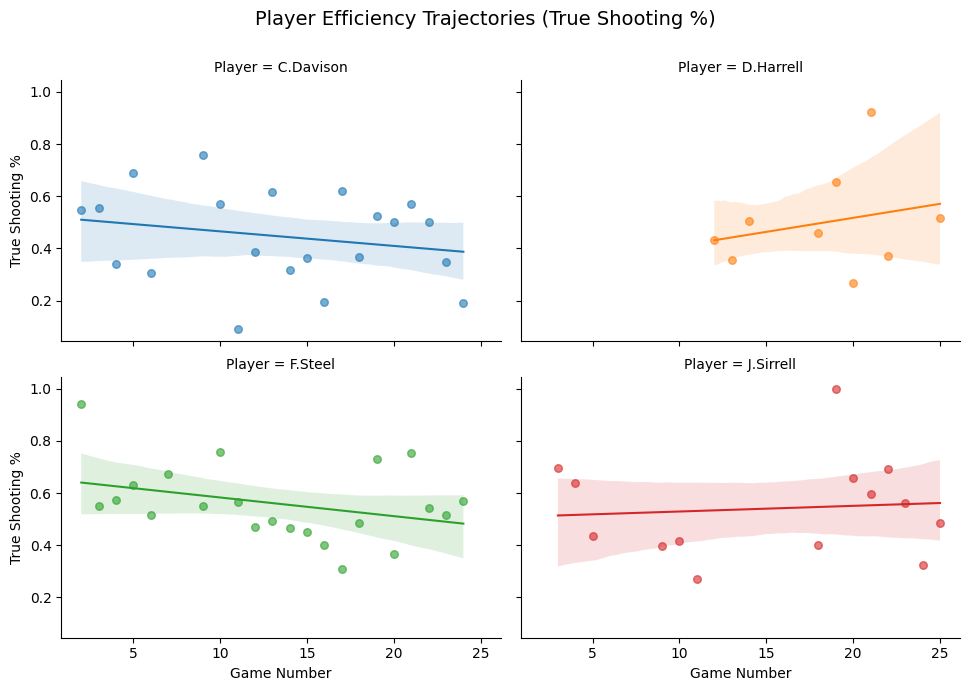

In [77]:
# Restrict to scorers with enough games for a reliable trend line, matching the threshold used in df_trends
eligible_players = df_trends['Player']
top_scorers = (
    df_active[df_active['Player'].isin(eligible_players)]
    .groupby('Player')['PTS'].sum()
    .nlargest(4).index
)

game_order = {g: i + 1 for i, g in enumerate(df_raw['Game_ID'].unique())}
df_active['Team_Game_No'] = df_active['Game_ID'].map(game_order)

# Filter df_top after mapping Team_Game_No so it contains the column
df_top = df_active[df_active['Player'].isin(top_scorers)]

# Plot TS% trajectory with linear regression lines
g = sns.lmplot(
    data=df_top,
    x='Team_Game_No',
    y='TS%',
    hue='Player',
    col='Player',
    col_wrap=2,
    height=3.5,
    aspect=1.4,
    scatter_kws={'alpha': 0.6, 's': 30},
    line_kws={'linewidth': 1.5}
)

g.set_axis_labels('Game Number', 'True Shooting %')
g.fig.subplots_adjust(top=0.88)
g.fig.suptitle('Player Efficiency Trajectories (True Shooting %)', fontsize=14)

plt.show()

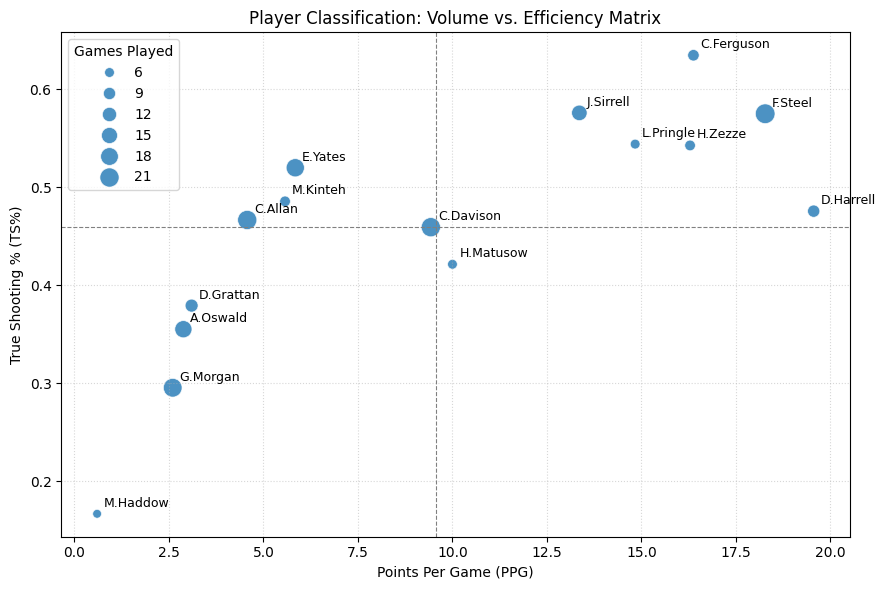

In [56]:
# Load data and standardize headers
df_overall = pd.read_excel(file_path, sheet_name='Overall Stats', header=1)
df_overall = df_overall.rename(columns={df_overall.columns[0]: 'Player'})

# Convert key fields to numeric
numeric_cols = ['Games Played', 'Total Points', 'PPG', '2ptA', '3ptA', 'ftA']
valid_cols = [c for c in numeric_cols if c in df_overall.columns]
df_overall[valid_cols] = df_overall[valid_cols].apply(pd.to_numeric, errors='coerce').fillna(0)

# Filter players meeting minimum game threshold
player_summary = df_overall[
    (df_overall['Player'].notna()) &
    (df_overall['Player'] != 'TEAM') &
    (df_overall['Games Played'] >= 5)
].copy()

# Calculate overall season True Shooting %
player_summary['FGA'] = player_summary['2ptA'] + player_summary['3ptA']
ts_denom = 2 * (player_summary['FGA'] + 0.44 * player_summary['ftA'])
player_summary['TS%'] = (player_summary['Total Points'] / ts_denom.replace(0, np.nan)).fillna(0)

# Calculate benchmark averages for quadrant axes
mean_pts = player_summary['PPG'].mean()
mean_ts = player_summary['TS%'].mean()

# Plot Matrix
fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    data=player_summary,
    x='PPG',
    y='TS%',
    size='Games Played',
    sizes=(40, 200),
    color='#1f77b4',
    alpha=0.8,
    ax=ax
)

# Reference quadrant lines
ax.axvline(mean_pts, color='gray', linestyle='--', linewidth=0.8)
ax.axhline(mean_ts, color='gray', linestyle='--', linewidth=0.8)

# Annotate points using point-offset spacing
for _, row in player_summary.iterrows():
    ax.annotate(
        row['Player'],
        (row['PPG'], row['TS%']),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=9
    )

ax.set_title('Player Classification: Volume vs. Efficiency Matrix', fontsize=12)
ax.set_xlabel('Points Per Game (PPG)')
ax.set_ylabel('True Shooting % (TS%)')
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

In [57]:
df_active = df_active.reset_index()

# Sort by Player first, then by the original row timeline
df_active = df_active.sort_values(['Player', 'index'])

# Clean up by dropping the temporary 'index' column and resetting the index cleanly
df_active = df_active.drop(columns=['index']).reset_index(drop=True)

# Assign game sequence per player
df_active['Game_Number'] = df_active.groupby('Player').cumcount() + 1

# Calculate 3-game rolling sums for volume stats
rolling_stats = (
    df_active.groupby('Player')[['PTS', 'FGA', 'ftA']]
    .rolling(window=3, min_periods=1)
    .sum()
    .reset_index(level=0, drop=True)
)

# Calculate the true volume-weighted rolling TS%
ts_denom = 2 * (rolling_stats['FGA'] + 0.44 * rolling_stats['ftA'])
df_active['TS%_3G_MA'] = (rolling_stats['PTS'] / ts_denom.replace(0, np.nan)).fillna(0)


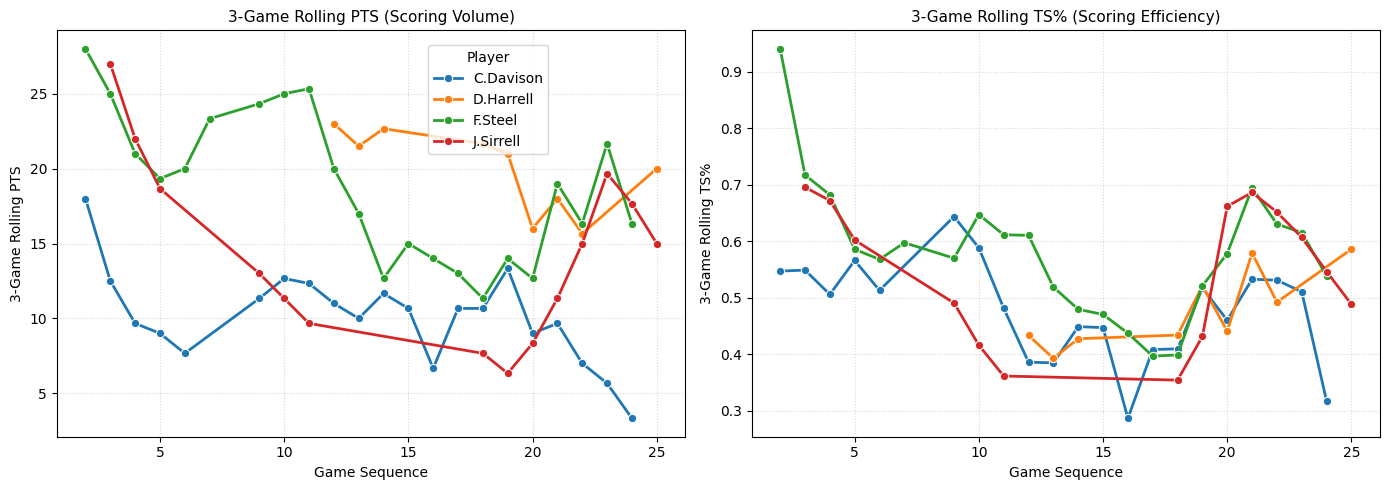

In [58]:
# Calculate 3-game rolling average for scoring volume
# (TS%_3G_MA is reused as-is from the volume-weighted version computed above)

game_order = {g: i + 1 for i, g in enumerate(df_raw['Game_ID'].unique())}
df_active['Team_Game_No'] = df_active['Game_ID'].map(game_order)


df_active['PTS_3G_MA'] = (
    df_active.groupby('Player')['PTS']
    .rolling(window=3, min_periods=1)
    .mean()
    .reset_index(level=0, drop=True)
)

# Filter for the top 4 scorers
top_scorers = player_summary.nlargest(4, 'Total Points')['Player']
df_rolling_top = df_active[df_active['Player'].isin(top_scorers)].copy()


# Plotting

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Points Scored Rolling Average
sns.lineplot(
    data=df_rolling_top,
    x='Team_Game_No',
    y='PTS_3G_MA',
    hue='Player',
    marker='o',
    linewidth=2,
    ax=axes[0]
)

sns.move_legend(axes[0], "upper left", bbox_to_anchor=(0.58, 0.98), frameon=True)
axes[0].set_title('3-Game Rolling PTS (Scoring Volume)', fontsize=11)
axes[0].set_xlabel('Game Sequence')
axes[0].set_ylabel('3-Game Rolling PTS')
axes[0].grid(True, linestyle=':', alpha=0.5)

# Plot 2: True Shooting % Rolling Average (volume-weighted)
sns.lineplot(
    data=df_rolling_top,
    x='Team_Game_No',
    y='TS%_3G_MA',
    hue='Player',
    marker='o',
    linewidth=2,
    ax=axes[1],
    legend=False  # Don't need a second legend
)

axes[1].set_title('3-Game Rolling TS% (Scoring Efficiency)', fontsize=11)
axes[1].set_xlabel('Game Sequence')
axes[1].set_ylabel('3-Game Rolling TS%')
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

In [59]:
from sklearn.tree import DecisionTreeClassifier, export_text

# Define game outcomes (1 = Win, 0 = Loss)
game_results = {
    'Blues H (F)': 1, 'Blues A (F)' : 0, 'Kings H' : 1, 'Rocks A' : 0, 'Paisley3 H' : 0, 'Wolves H' : 1, 'Blaze A' : 0, 'Ignite H' : 1, 'Paisley H': 0, 'Blues H' : 1, 'Kings2 H' : 0, 'Fury A' : 0, 'Blaze2 A' : 0, 'Ignite2 H' : 1, 'Rocks H' : 0, 'Paisley A' : 0, 'Fury2 A' : 0, 'Blaze H' : 0, 'Blues A' : 1, 'Kings A' : 0, 'Blues2 H' : 1, 'Fury H' : 0, 'Ignite A' : 1, 'Rocks2 A' : 0, 'Paisley2 H' : 1
}

game_metrics = []

# Extract metrics per game
for game_id, group in df_raw.groupby('Game_ID'):
  if group['Is_Friendly'].iloc[0]:
    continue

  is_team = group['Player'] == 'TEAM'
  players = group[~is_team]
  team_row = group[is_team]

  # Top 3 Scorers Combined Points
  top3_pts = players['PTS'].nlargest(3).sum()

  # Check for team row
  if not team_row.empty:
      stats = team_row.iloc[0]
      reb = stats.get('REB', players['REB'].sum())
      ast, tov, pts = stats['AST'], stats['TOV'], stats['PTS']
      fga = stats['2ptA'] + stats['3ptA']
      fta = stats['ftA']
  else:
      # Fallback: aggregate all players if the TEAM row is missing entirely
      reb = players['REB'].sum()
      ast, tov, pts = players['AST'].sum(), players['TOV'].sum(), players['PTS'].sum()
      fga = players['2ptA'].sum() + players['3ptA'].sum()
      fta = players['ftA'].sum()

  # Calculate ratios
  ast_tov = ast / tov if tov > 0 else ast
  ts_denom = 2 * (fga + 0.44 * fta)
  team_ts = pts / ts_denom if ts_denom > 0 else 0.0

  game_metrics.append({
      'Game_ID': game_id,
      'Top3_PTS': top3_pts,
      'Team_REB': reb,
      'Team_AST_TOV': ast_tov,
      'Team_TS%': team_ts
  })

# Build DataFrame and map target variables vectorially
df_games = pd.DataFrame(game_metrics)
df_games['Win'] = df_games['Game_ID'].map(game_results)
df_games = df_games.dropna(subset=['Win']).copy()
df_games['Win'] = df_games['Win'].astype(int)

# Decision Tree

features = ['Top3_PTS', 'Team_REB', 'Team_AST_TOV', 'Team_TS%']
X = df_games[features]
y = df_games['Win']

# Initialize tree
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X, y)

# Print the numerical splits the model calculated for your metrics
print("Decision Tree Benchmarks:\n")
print(export_text(tree_model, feature_names=features))

Decision Tree Benchmarks:

|--- Team_REB <= 43.50
|   |--- Top3_PTS <= 57.00
|   |   |--- class: 0
|   |--- Top3_PTS >  57.00
|   |   |--- Team_TS% <= 0.54
|   |   |   |--- class: 0
|   |   |--- Team_TS% >  0.54
|   |   |   |--- class: 1
|--- Team_REB >  43.50
|   |--- class: 1



WIN vs LOSS BENCHMARKS
Win                          0          1
Top3_PTS_mean        48.000000  62.333333
Top3_PTS_median      49.000000  65.000000
Top3_PTS_pct_25      44.000000  60.000000
Team_REB_mean        35.785714  46.111111
Team_REB_median      36.500000  46.000000
Team_REB_pct_25      32.500000  42.000000
Team_AST_TOV_mean     0.751718   1.400316
Team_AST_TOV_median   0.711111   1.400000
Team_AST_TOV_pct_25   0.522059   0.904762
Team_TS%_mean         0.470735   0.517889
Team_TS%_median       0.478865   0.561358
Team_TS%_pct_25       0.453351   0.407000




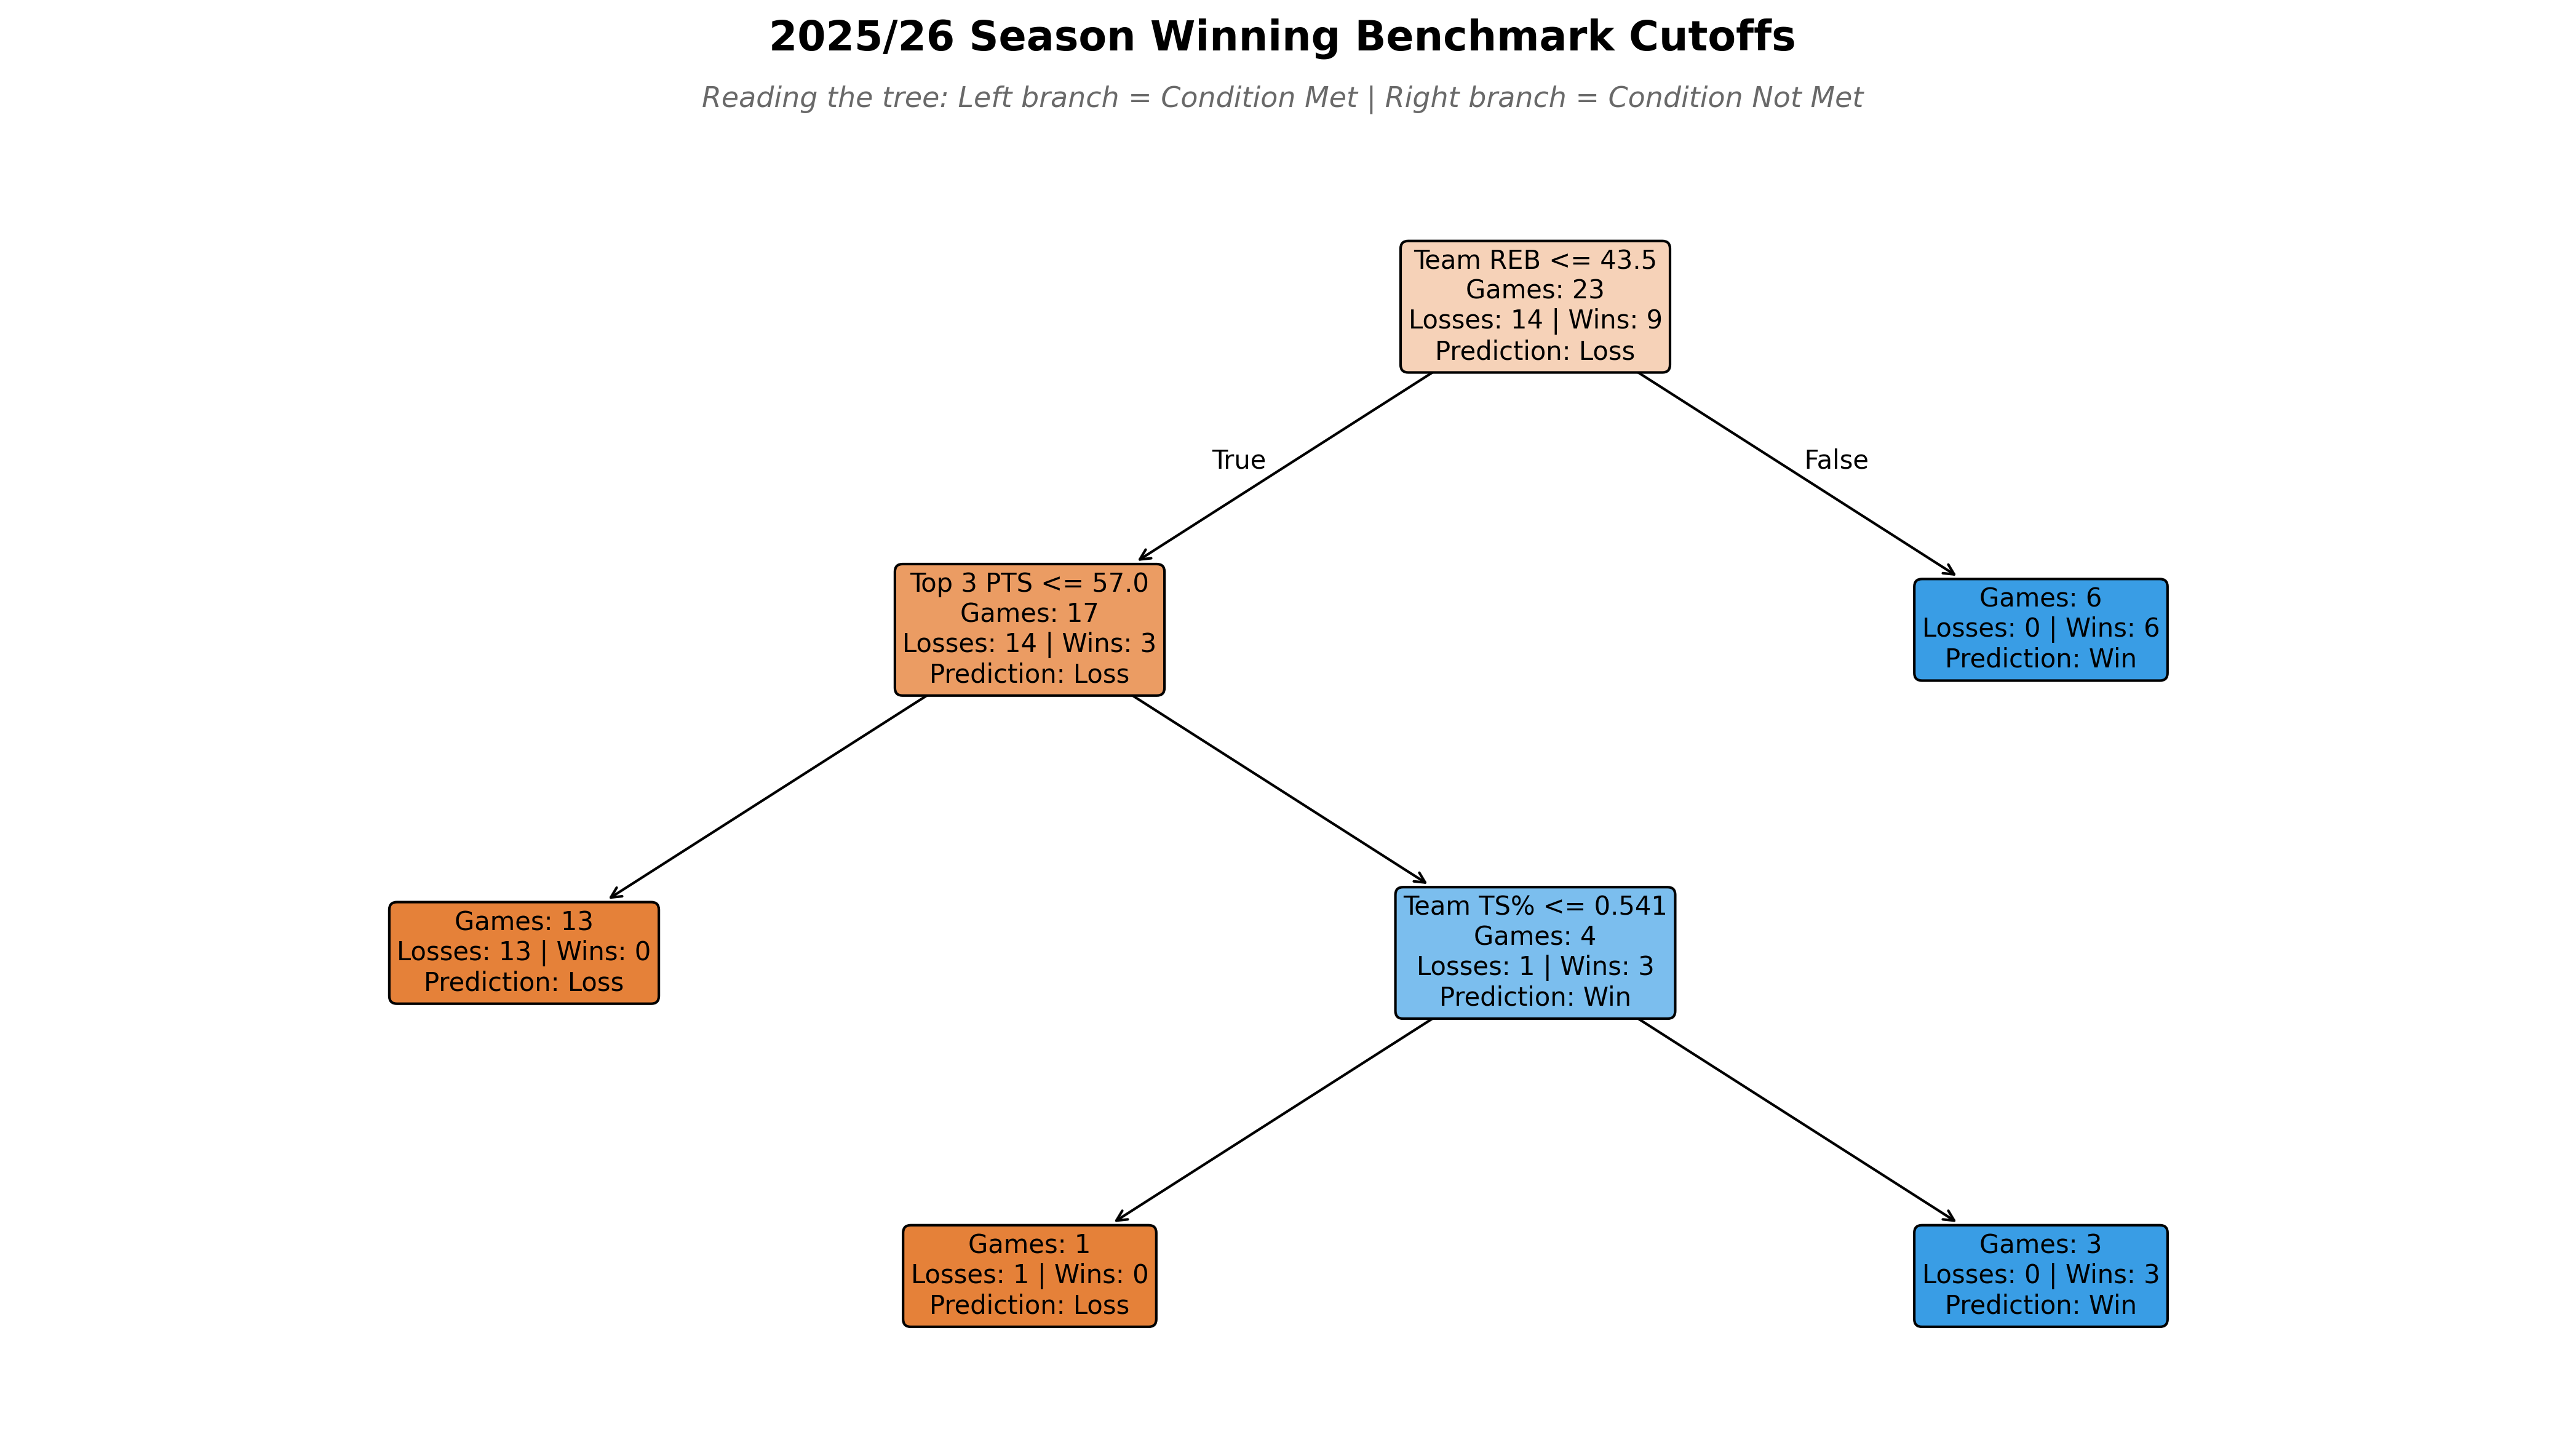

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Clean benchmark summary

def pct_25(x): return np.percentile(x, 25)

benchmark_summary = df_games.groupby('Win')[['Top3_PTS', 'Team_REB', 'Team_AST_TOV', 'Team_TS%']].agg(
    ['mean', 'median', pct_25]
)

benchmark_summary.columns = [f'{col}_{stat}' for col, stat in benchmark_summary.columns]
print("WIN vs LOSS BENCHMARKS")
print(benchmark_summary.T)
print("\n")


# Decision Tree Visualisation
features = ['Top3_PTS', 'Team_REB', 'Team_AST_TOV', 'Team_TS%']
X = df_games[features]
y = df_games['Win']

tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X, y)

fig, ax = plt.subplots(figsize=(14, 8), dpi=300)

annotations = plot_tree(
    tree_model,
    feature_names=['Top 3 PTS', 'Team REB', 'AST/TOV Ratio', 'Team TS%'],
    class_names=['Loss', 'Win'],
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=10,
    ax=ax
)

# Rewrite node text to improve readability
for text_obj in annotations:
    raw_text = text_obj.get_text()
    lines = raw_text.split('\n')

    new_lines = []
    for line in lines:
        if 'samples =' in line:
            games_count = line.split('=')[1].strip()
            new_lines.append(f"Games: {games_count}")
        elif 'value =' in line:
            raw_vals = line.split('=')[1].strip().strip('[]').split(',')
            if len(raw_vals) == 2:
                losses, wins = raw_vals[0].strip(), raw_vals[1].strip()
                new_lines.append(f"Losses: {losses} | Wins: {wins}")
            else:
                new_lines.append(line)
        elif 'class =' in line:
            outcome = line.split('=')[1].strip()
            new_lines.append(f"Prediction: {outcome}")
        else:
            new_lines.append(line)

    text_obj.set_text('\n'.join(new_lines))

# Title and subtitle explaining the branches
plt.suptitle('2025/26 Season Winning Benchmark Cutoffs', fontsize=16, fontweight='bold', y=0.98)

plt.title('Reading the tree: Left branch = Condition Met | Right branch = Condition Not Met',
          fontsize=11, fontstyle='italic', color='dimgray', pad=15)

plt.tight_layout()
plt.show()

In [61]:
# Check feature importance breakdown
importances = pd.Series(tree_model.feature_importances_, index=features)
print("Feature Importance Breakdown:")
print(importances.sort_values(ascending=False))

Feature Importance Breakdown:
Team_REB        0.549020
Top3_PTS        0.314076
Team_TS%        0.136905
Team_AST_TOV    0.000000
dtype: float64


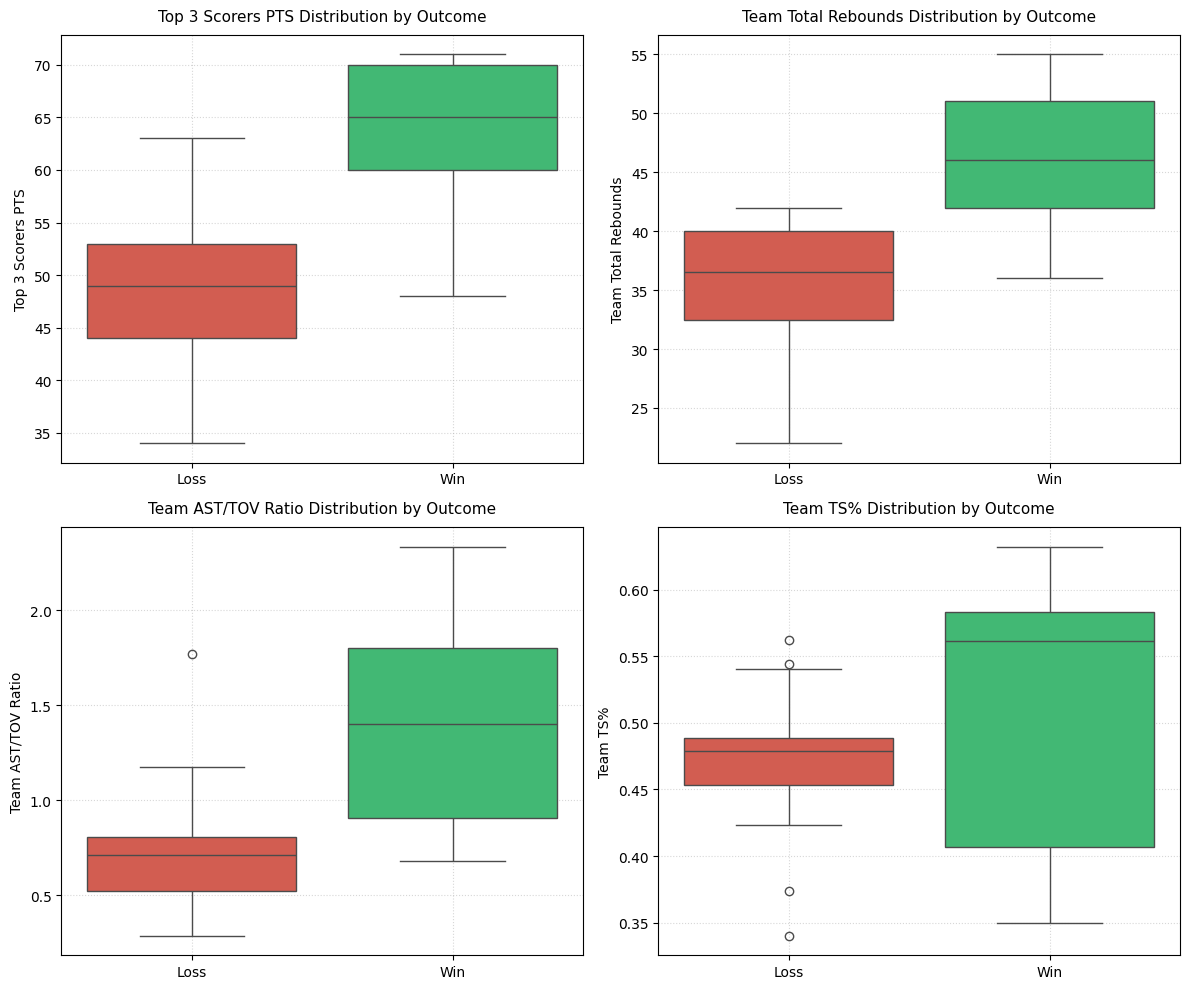

In [62]:
# Create a temporary plotting copy with clear categorical labels
df_plot = df_games.copy()
df_plot['Outcome'] = df_plot['Win'].map({0: 'Loss', 1: 'Win'})

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

metrics = [
    ('Top3_PTS', 'Top 3 Scorers PTS'),
    ('Team_REB', 'Team Total Rebounds'),
    ('Team_AST_TOV', 'Team AST/TOV Ratio'),
    ('Team_TS%', 'Team TS%')
]

for ax, (col, title) in zip(axes.flatten(), metrics):
    sns.boxplot(
        data=df_plot,
        x='Outcome',
        y=col,
        hue='Outcome',
        palette=['#e74c3c', '#2ecc71'],
        legend=False,
        ax=ax
    )
    ax.set_title(f'{title} Distribution by Outcome', fontsize=11, pad=10)
    ax.set_xlabel('')
    ax.set_ylabel(title)
    ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

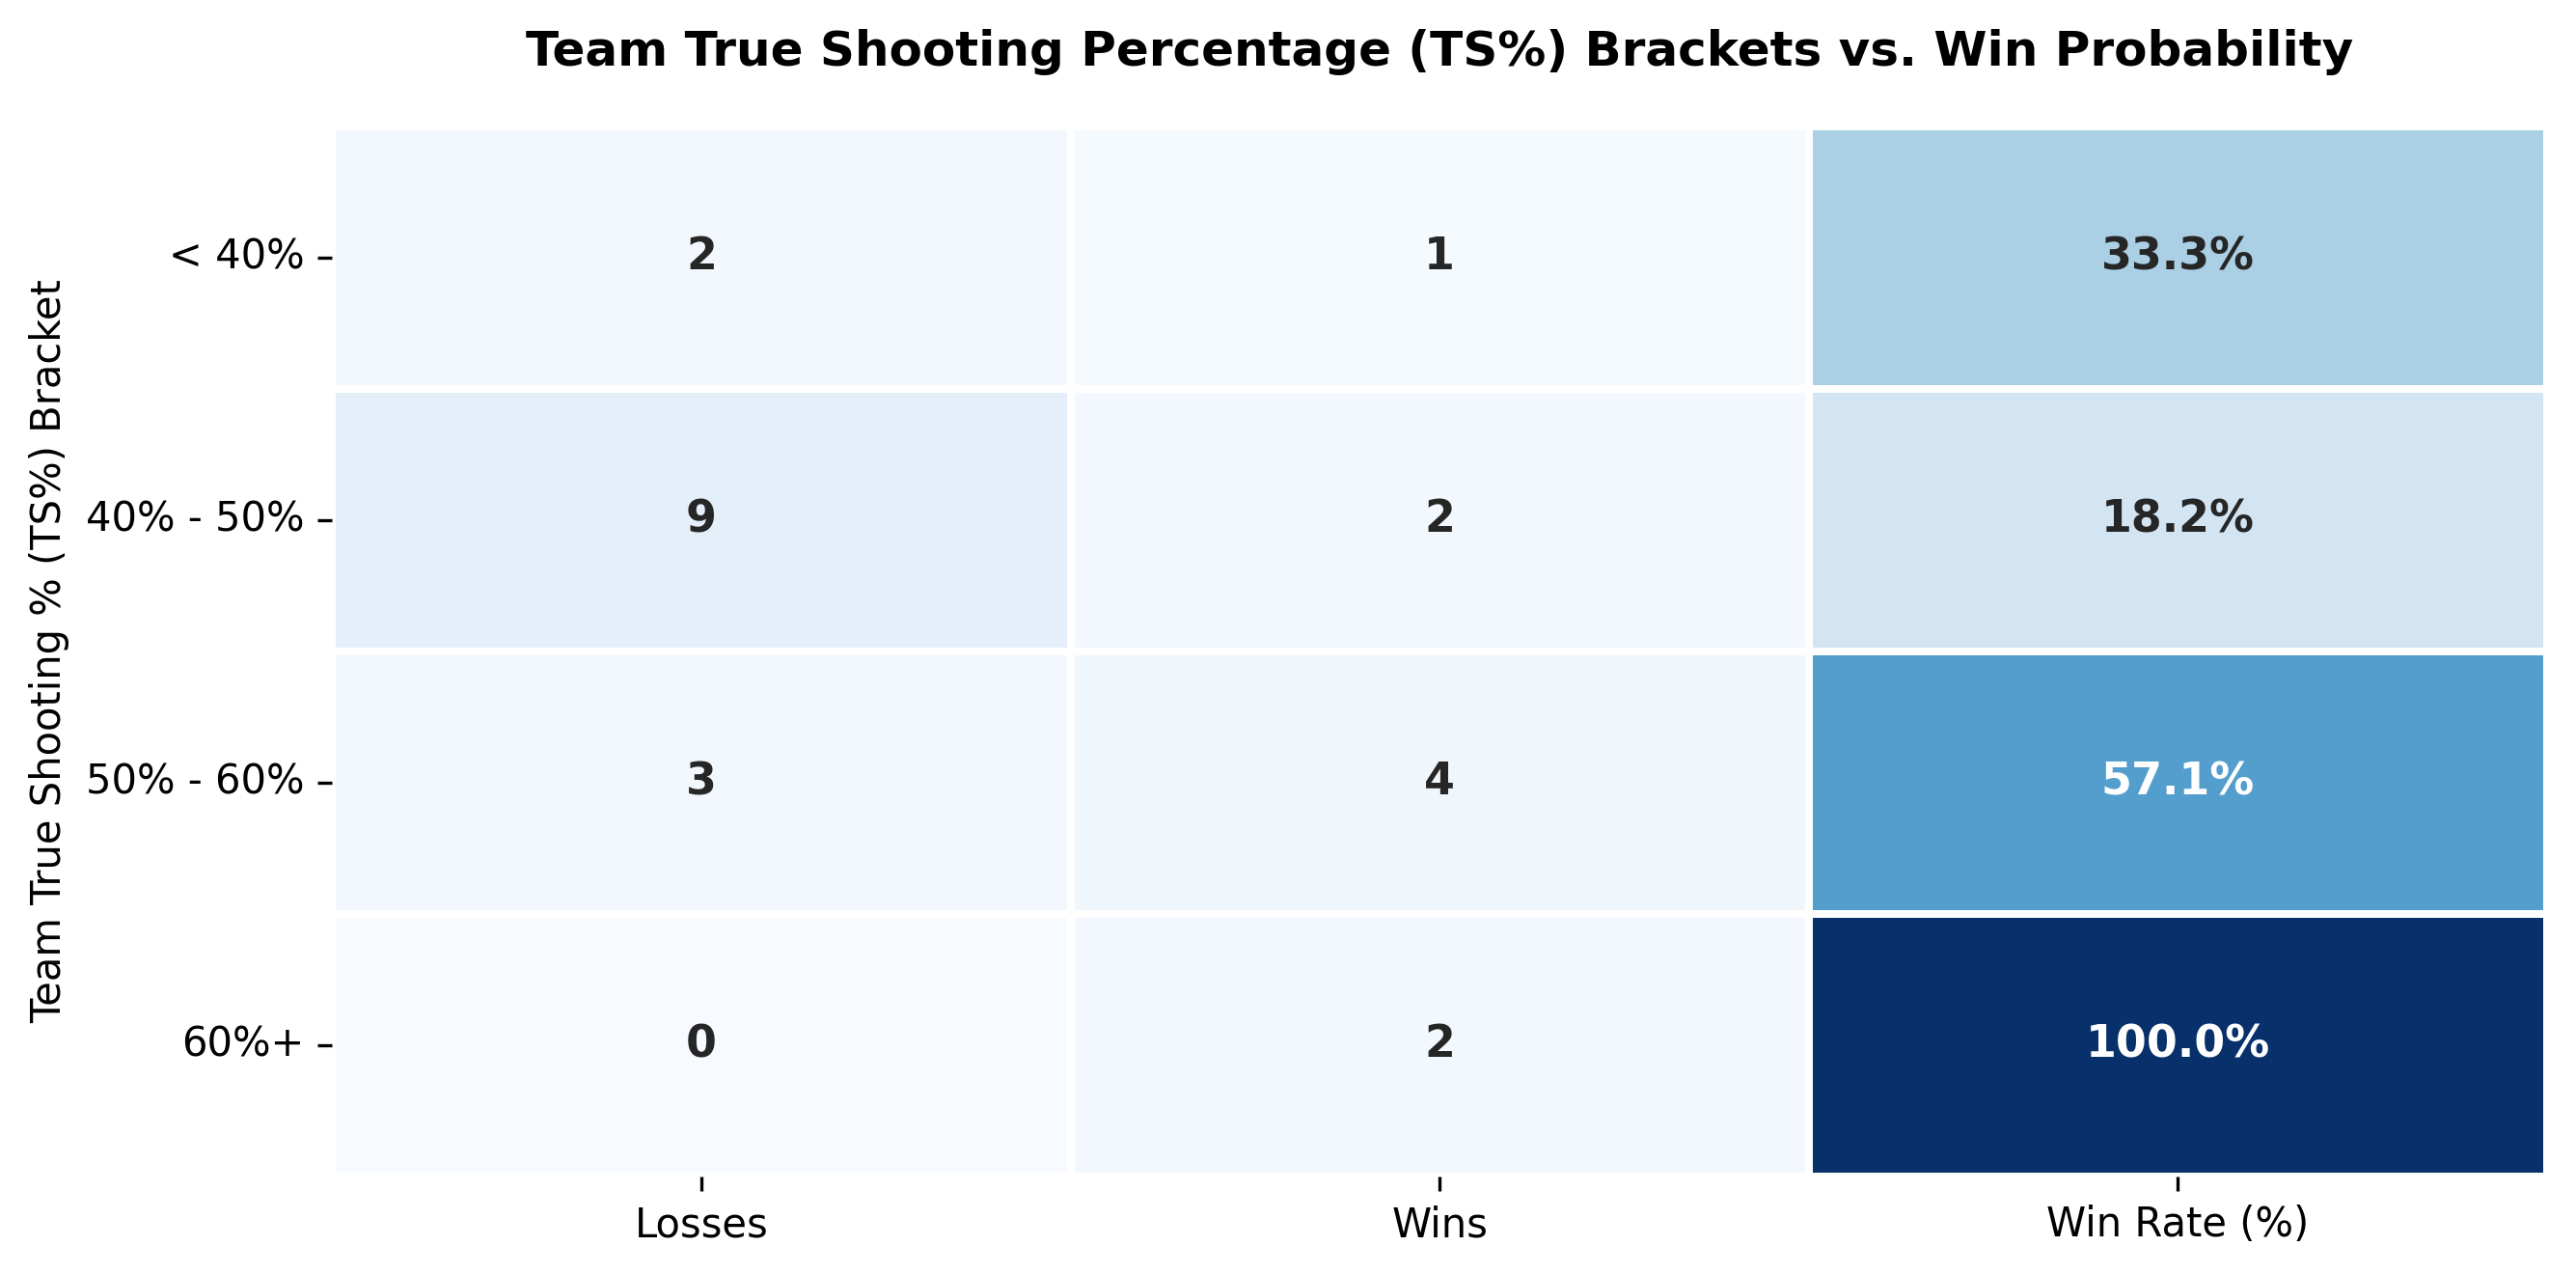

In [63]:
# Define custom bin edges and labels for Team TS%
bin_edges = [0.0, 0.40, 0.50, 0.60, 1.00]
bin_labels = ['< 40%', '40% - 50%', '50% - 60%', '60%+']

df_games['TS_Bin'] = pd.cut(
    df_games['Team_TS%'], bins=bin_edges, labels=bin_labels, include_lowest=True
)

# Cross-tabulate TS% bins vs Win/Loss status
ct = pd.crosstab(df_games['TS_Bin'], df_games['Win'])

# Guarantee columns 0 (Losses) and 1 (Wins) exist
for col in [0, 1]:
  if col not in ct.columns:
    ct[col] = 0

ct = ct.rename(columns={0: 'Losses', 1: 'Wins'})

# Reindex to ensure all defined bin labels appear in order
ct = ct.reindex(bin_labels, fill_value=0)

# Calculate totals and win percentage
ct['Total Games'] = ct['Losses'] + ct['Wins']
ct['Win Rate (%)'] = np.where(
    ct['Total Games'] > 0, (ct['Wins'] / ct['Total Games'] * 100), 0.0
).round(1)

ct_display = ct[['Losses', 'Wins', 'Win Rate (%)']]

annot_matrix = ct_display.copy().astype(object)
annot_matrix['Losses'] = ct_display['Losses'].astype(str)
annot_matrix['Wins'] = ct_display['Wins'].astype(str)
annot_matrix['Win Rate (%)'] = ct_display['Win Rate (%)'].apply(
    lambda x: f'{x:.1f}%'
)


# Heat Map

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=300)

sns.heatmap(
    ct_display,
    annot=annot_matrix.values,
    fmt='',
    cmap='Blues',
    cbar=False,
    linewidths=1.5,
    linecolor='white',
    annot_kws={'size': 11, 'weight': 'bold'},
    ax=ax,
)

ax.set_title(
    'Team True Shooting Percentage (TS%) Brackets vs. Win Probability',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
ax.set_ylabel('Team True Shooting % (TS%) Bracket')
ax.tick_params(axis='y', rotation=0)

ax.set_xlabel(
    ''
)

plt.tight_layout()
plt.show()

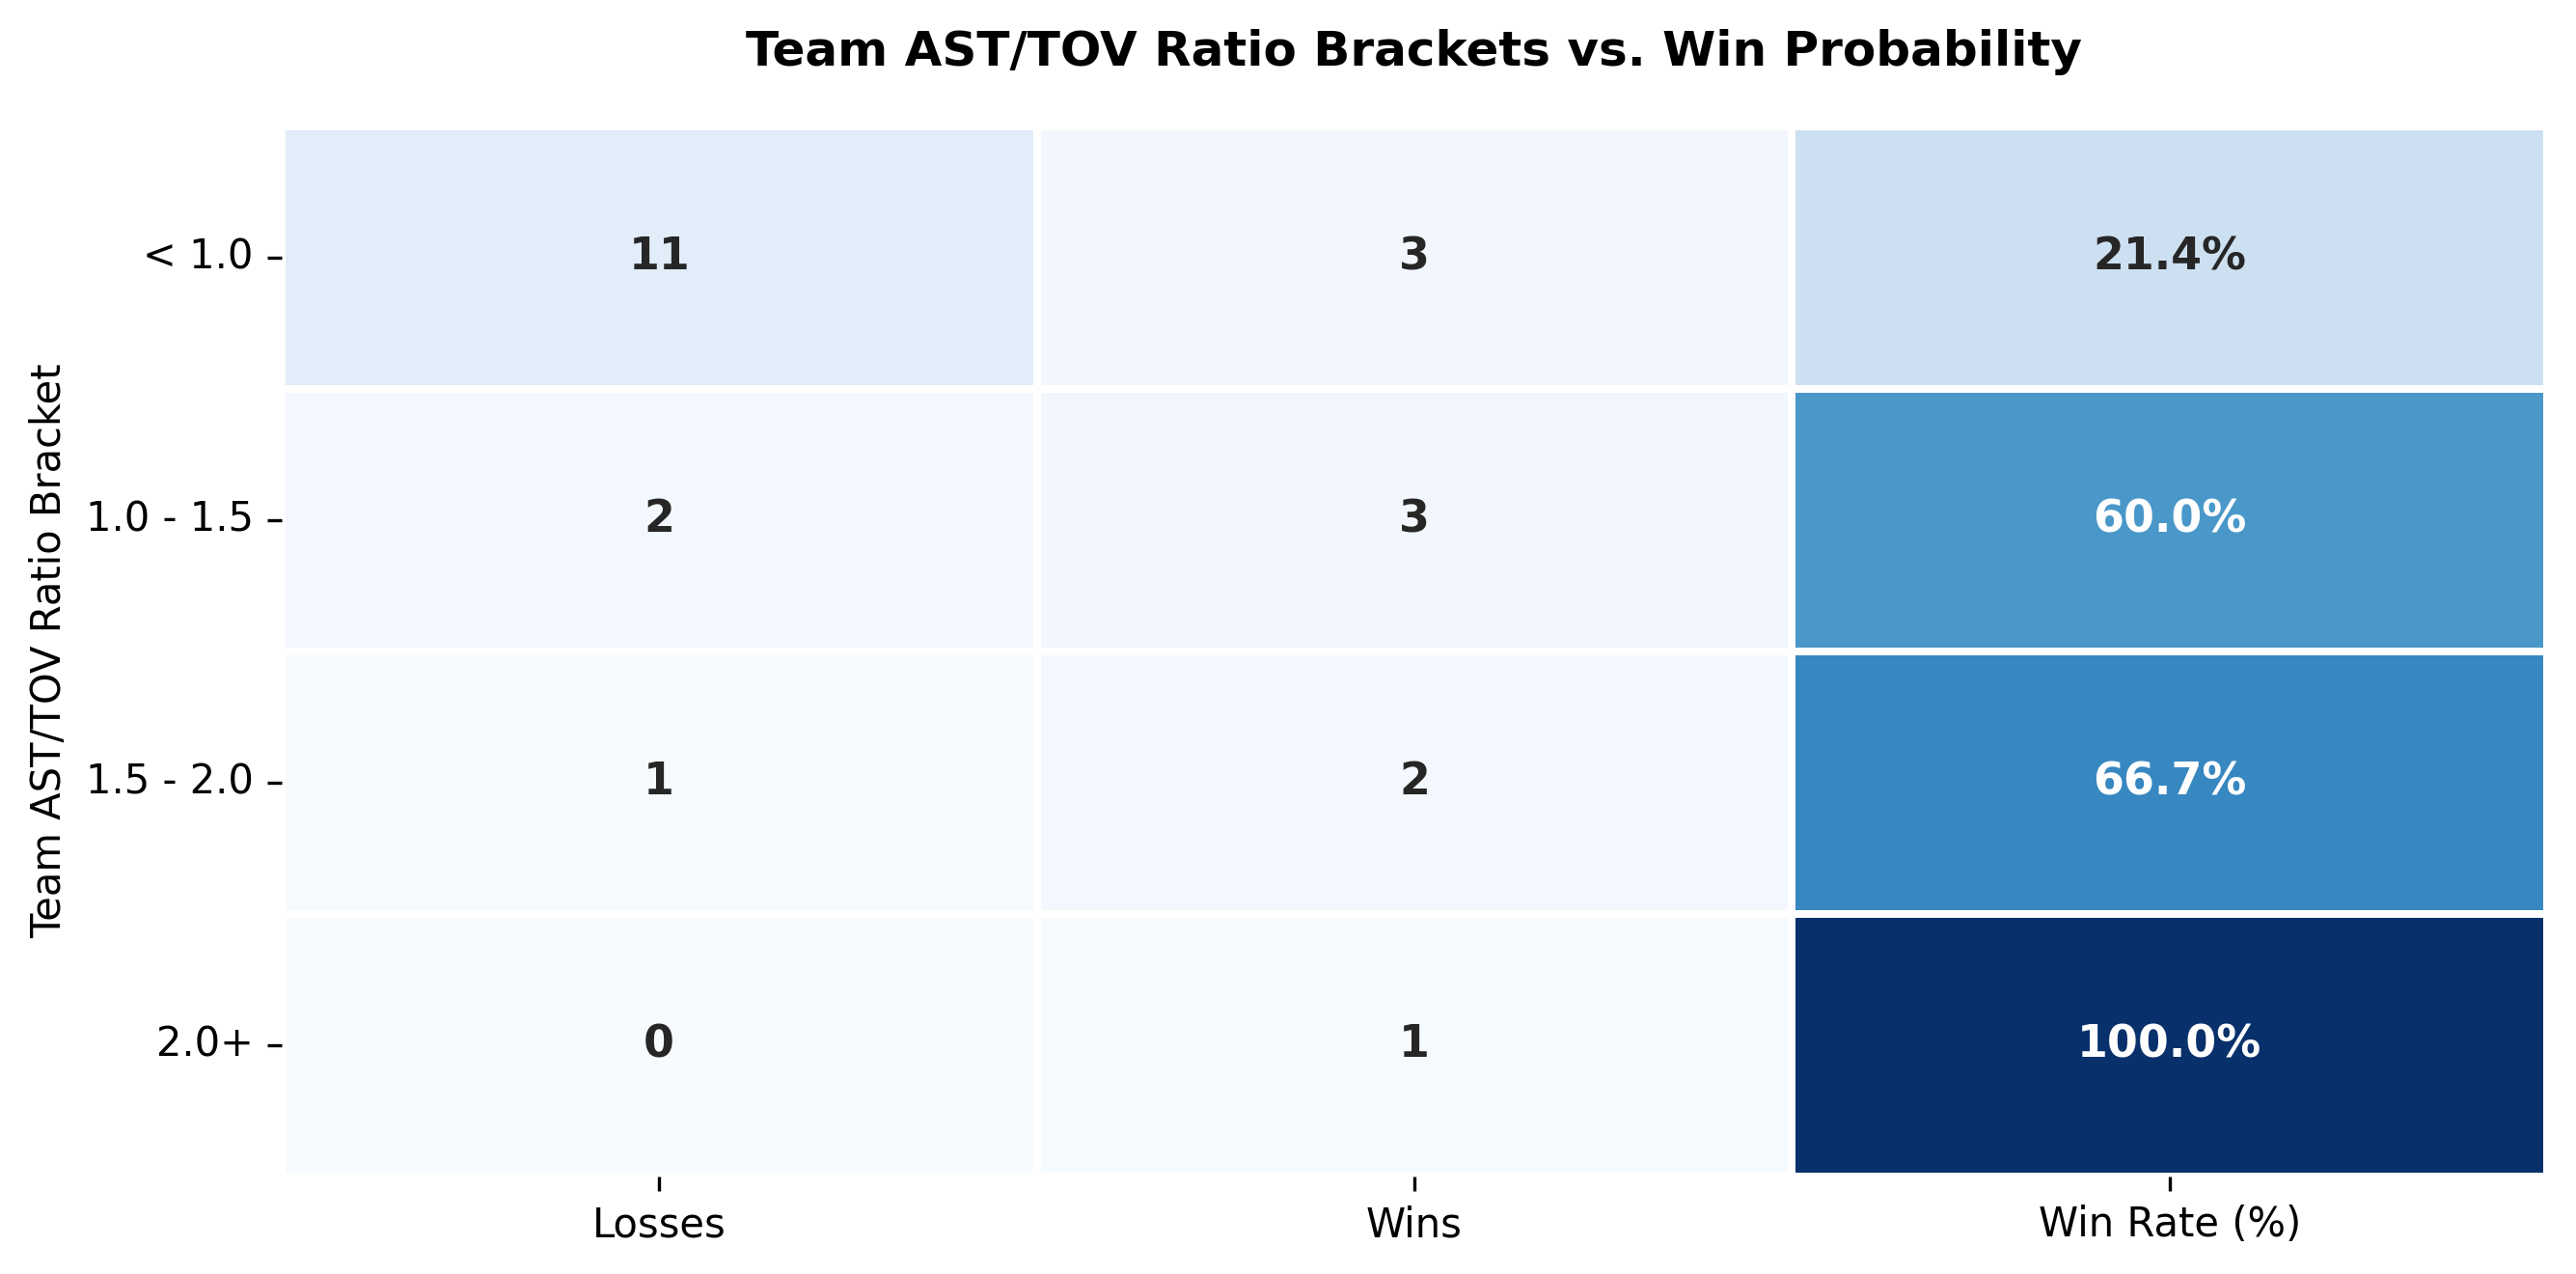

In [64]:
# Define custom bin edges and labels for Team AST/TOV Ratio
bin_edges = [0.0, 1.0, 1.5, 2.0, float('inf')]
bin_labels = ['< 1.0', '1.0 - 1.5', '1.5 - 2.0', '2.0+']

df_games['AST_TOV_Bin'] = pd.cut(
    df_games['Team_AST_TOV'], bins=bin_edges, labels=bin_labels, include_lowest=True
)

# Cross-tabulate AST/TOV bins vs Win/Loss status
ct = pd.crosstab(df_games['AST_TOV_Bin'], df_games['Win'])

# Guarantee columns 0 (Losses) and 1 (Wins) exist
for col in [0, 1]:
  if col not in ct.columns:
    ct[col] = 0

ct = ct.rename(columns={0: 'Losses', 1: 'Wins'})

ct = ct.reindex(bin_labels, fill_value=0)

ct['Total Games'] = ct['Losses'] + ct['Wins']
ct['Win Rate (%)'] = np.where(
    ct['Total Games'] > 0, (ct['Wins'] / ct['Total Games'] * 100), 0.0
).round(1)

ct_display = ct[['Losses', 'Wins', 'Win Rate (%)']]

annot_matrix = ct_display.copy().astype(object)
annot_matrix['Losses'] = ct_display['Losses'].astype(str)
annot_matrix['Wins'] = ct_display['Wins'].astype(str)
annot_matrix['Win Rate (%)'] = ct_display['Win Rate (%)'].apply(
    lambda x: f'{x:.1f}%'
)

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=300)

sns.heatmap(
    ct_display,
    annot=annot_matrix.values,
    fmt='',
    cmap='Blues',
    cbar=False,
    linewidths=1.5,
    linecolor='white',
    annot_kws={'size': 11, 'weight': 'bold'},
    ax=ax,
)

ax.set_title(
    'Team AST/TOV Ratio Brackets vs. Win Probability',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
ax.set_ylabel('Team AST/TOV Ratio Bracket')
ax.tick_params(axis='y', rotation=0)

ax.set_xlabel(
    ''
)

plt.tight_layout()
plt.show()

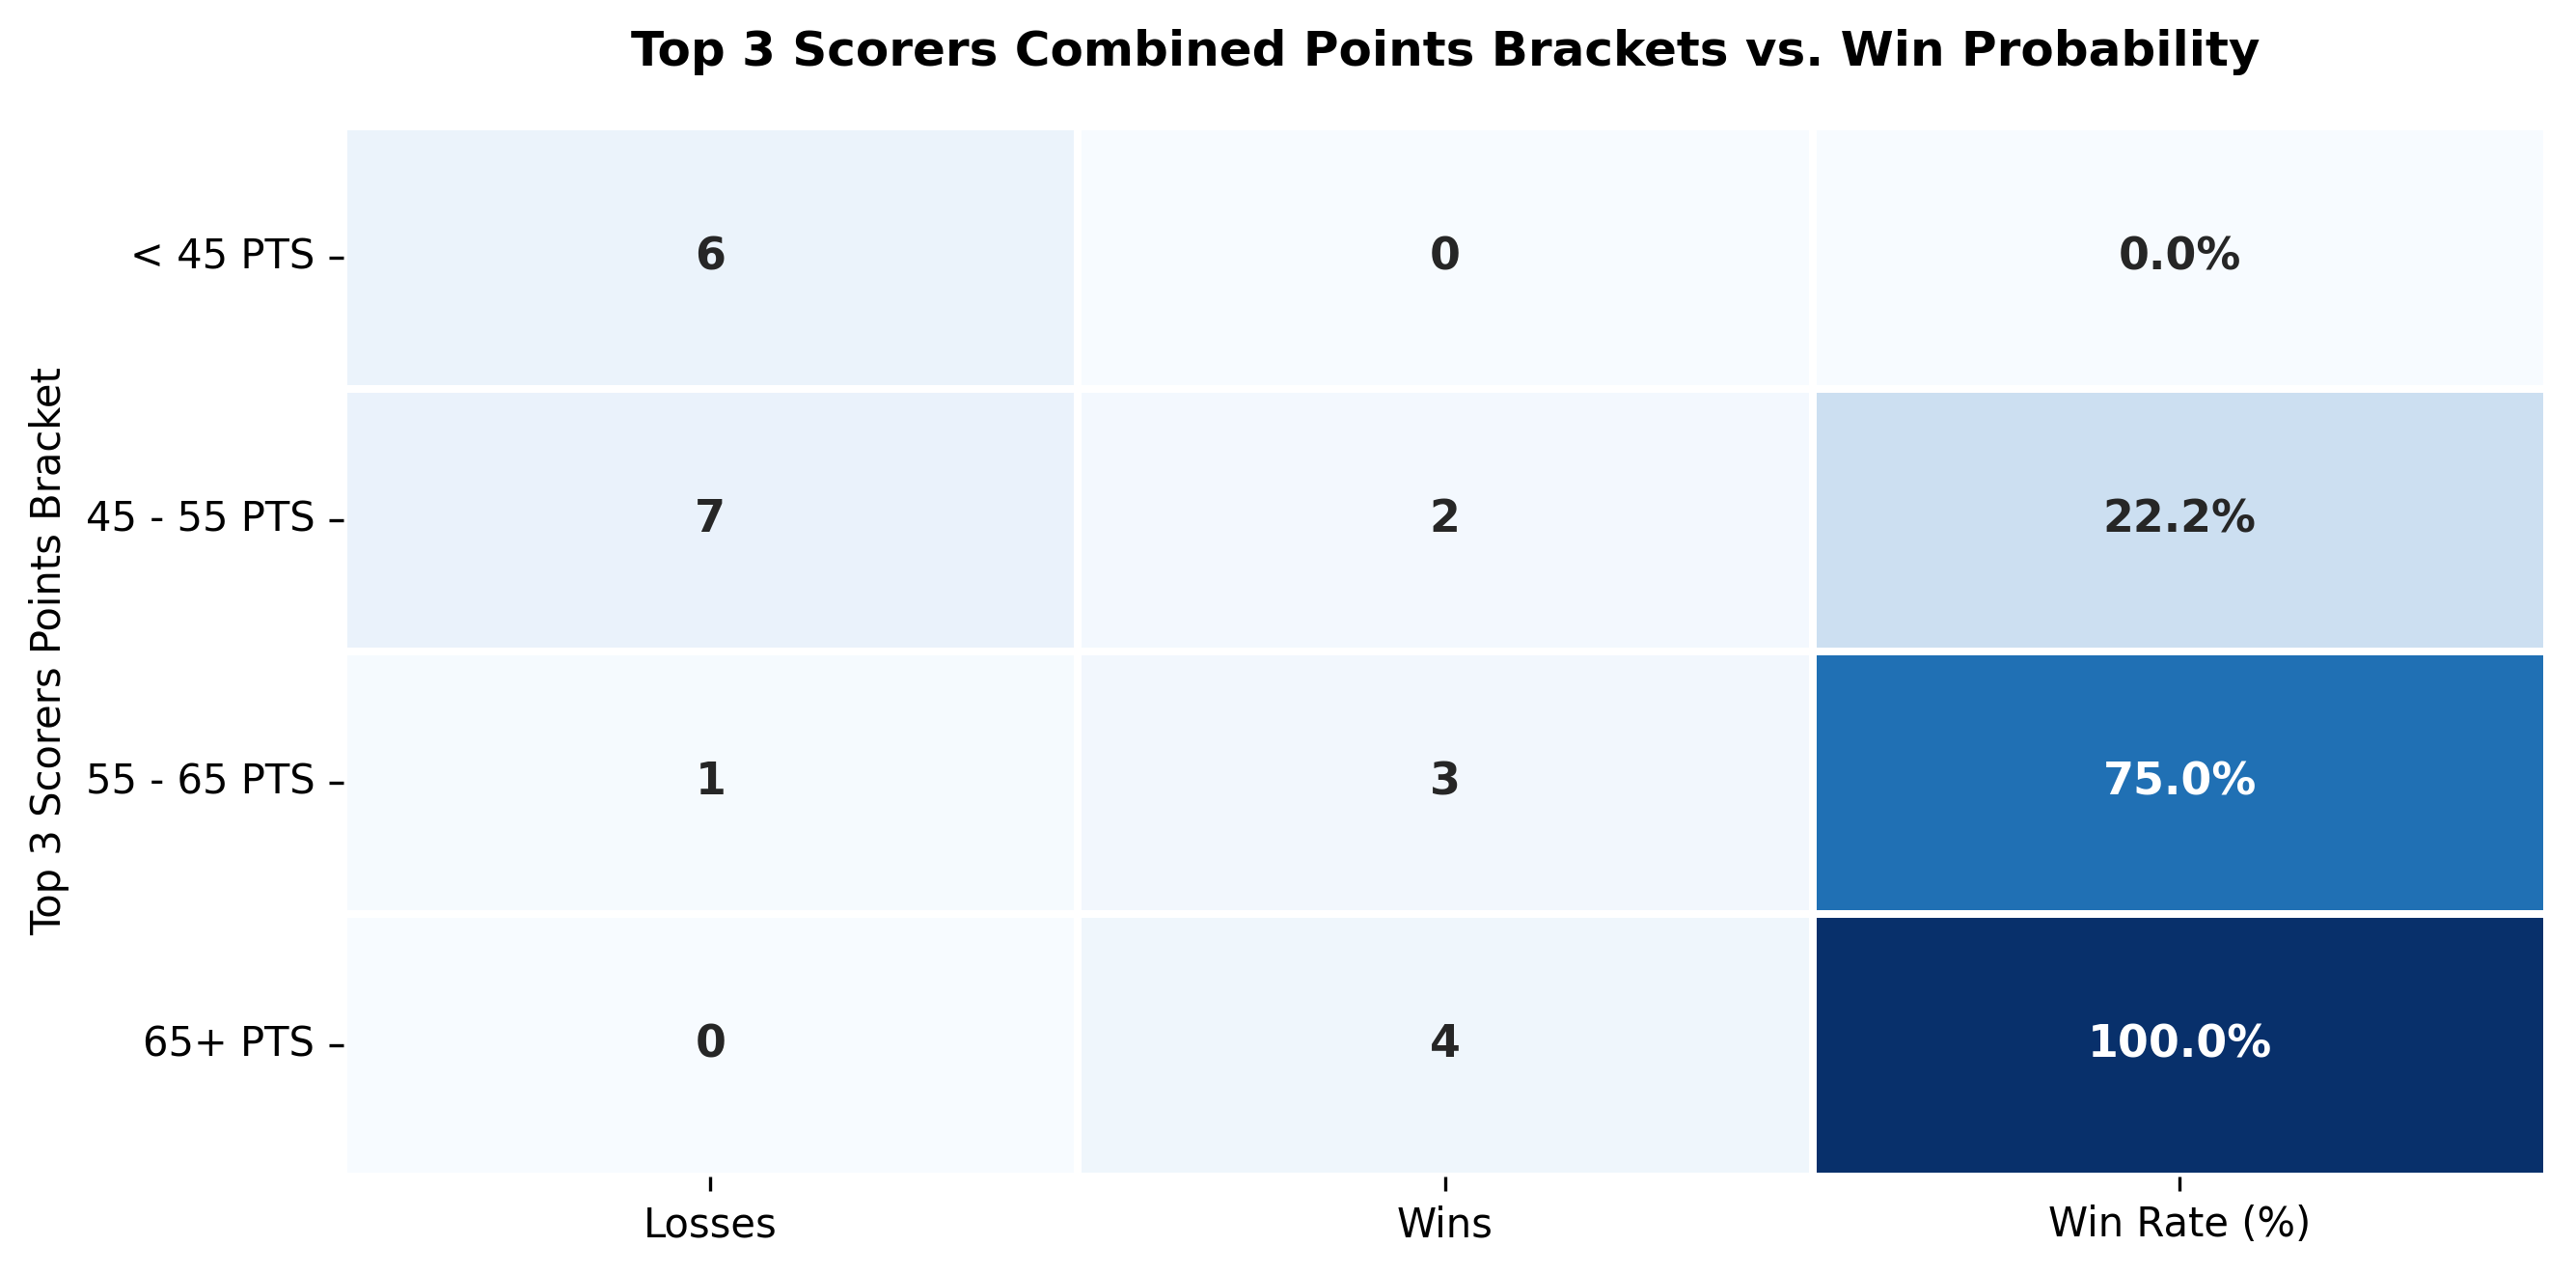

In [65]:
bin_edges = [0, 45, 55, 65, float('inf')]
bin_labels = ['< 45 PTS', '45 - 55 PTS', '55 - 65 PTS', '65+ PTS']

df_games['Top3_PTS_Bin'] = pd.cut(
    df_games['Top3_PTS'],
    bins=bin_edges,
    labels=bin_labels,
    include_lowest=True,
)

ct = pd.crosstab(df_games['Top3_PTS_Bin'], df_games['Win'])

for col in [0, 1]:
  if col not in ct.columns:
    ct[col] = 0

ct = ct.rename(columns={0: 'Losses', 1: 'Wins'})
ct = ct.reindex(bin_labels, fill_value=0)

ct['Total Games'] = ct['Losses'] + ct['Wins']
ct['Win Rate (%)'] = np.where(
    ct['Total Games'] > 0, (ct['Wins'] / ct['Total Games'] * 100), 0.0
).round(1)

ct_display = ct[['Losses', 'Wins', 'Win Rate (%)']]

annot_matrix = ct_display.copy().astype(object)
annot_matrix['Losses'] = ct_display['Losses'].astype(str)
annot_matrix['Wins'] = ct_display['Wins'].astype(str)
annot_matrix['Win Rate (%)'] = ct_display['Win Rate (%)'].apply(
    lambda x: f'{x:.1f}%'
)

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=300)

sns.heatmap(
    ct_display,
    annot=annot_matrix.values,
    fmt='',
    cmap='Blues',
    cbar=False,
    linewidths=1.5,
    linecolor='white',
    annot_kws={'size': 11, 'weight': 'bold'},
    ax=ax,
)

ax.set_title(
    'Top 3 Scorers Combined Points Brackets vs. Win Probability',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
ax.set_ylabel('Top 3 Scorers Points Bracket')
ax.tick_params(axis='y', rotation=0)

ax.set_xlabel(
    ''
)

plt.tight_layout()
plt.show()

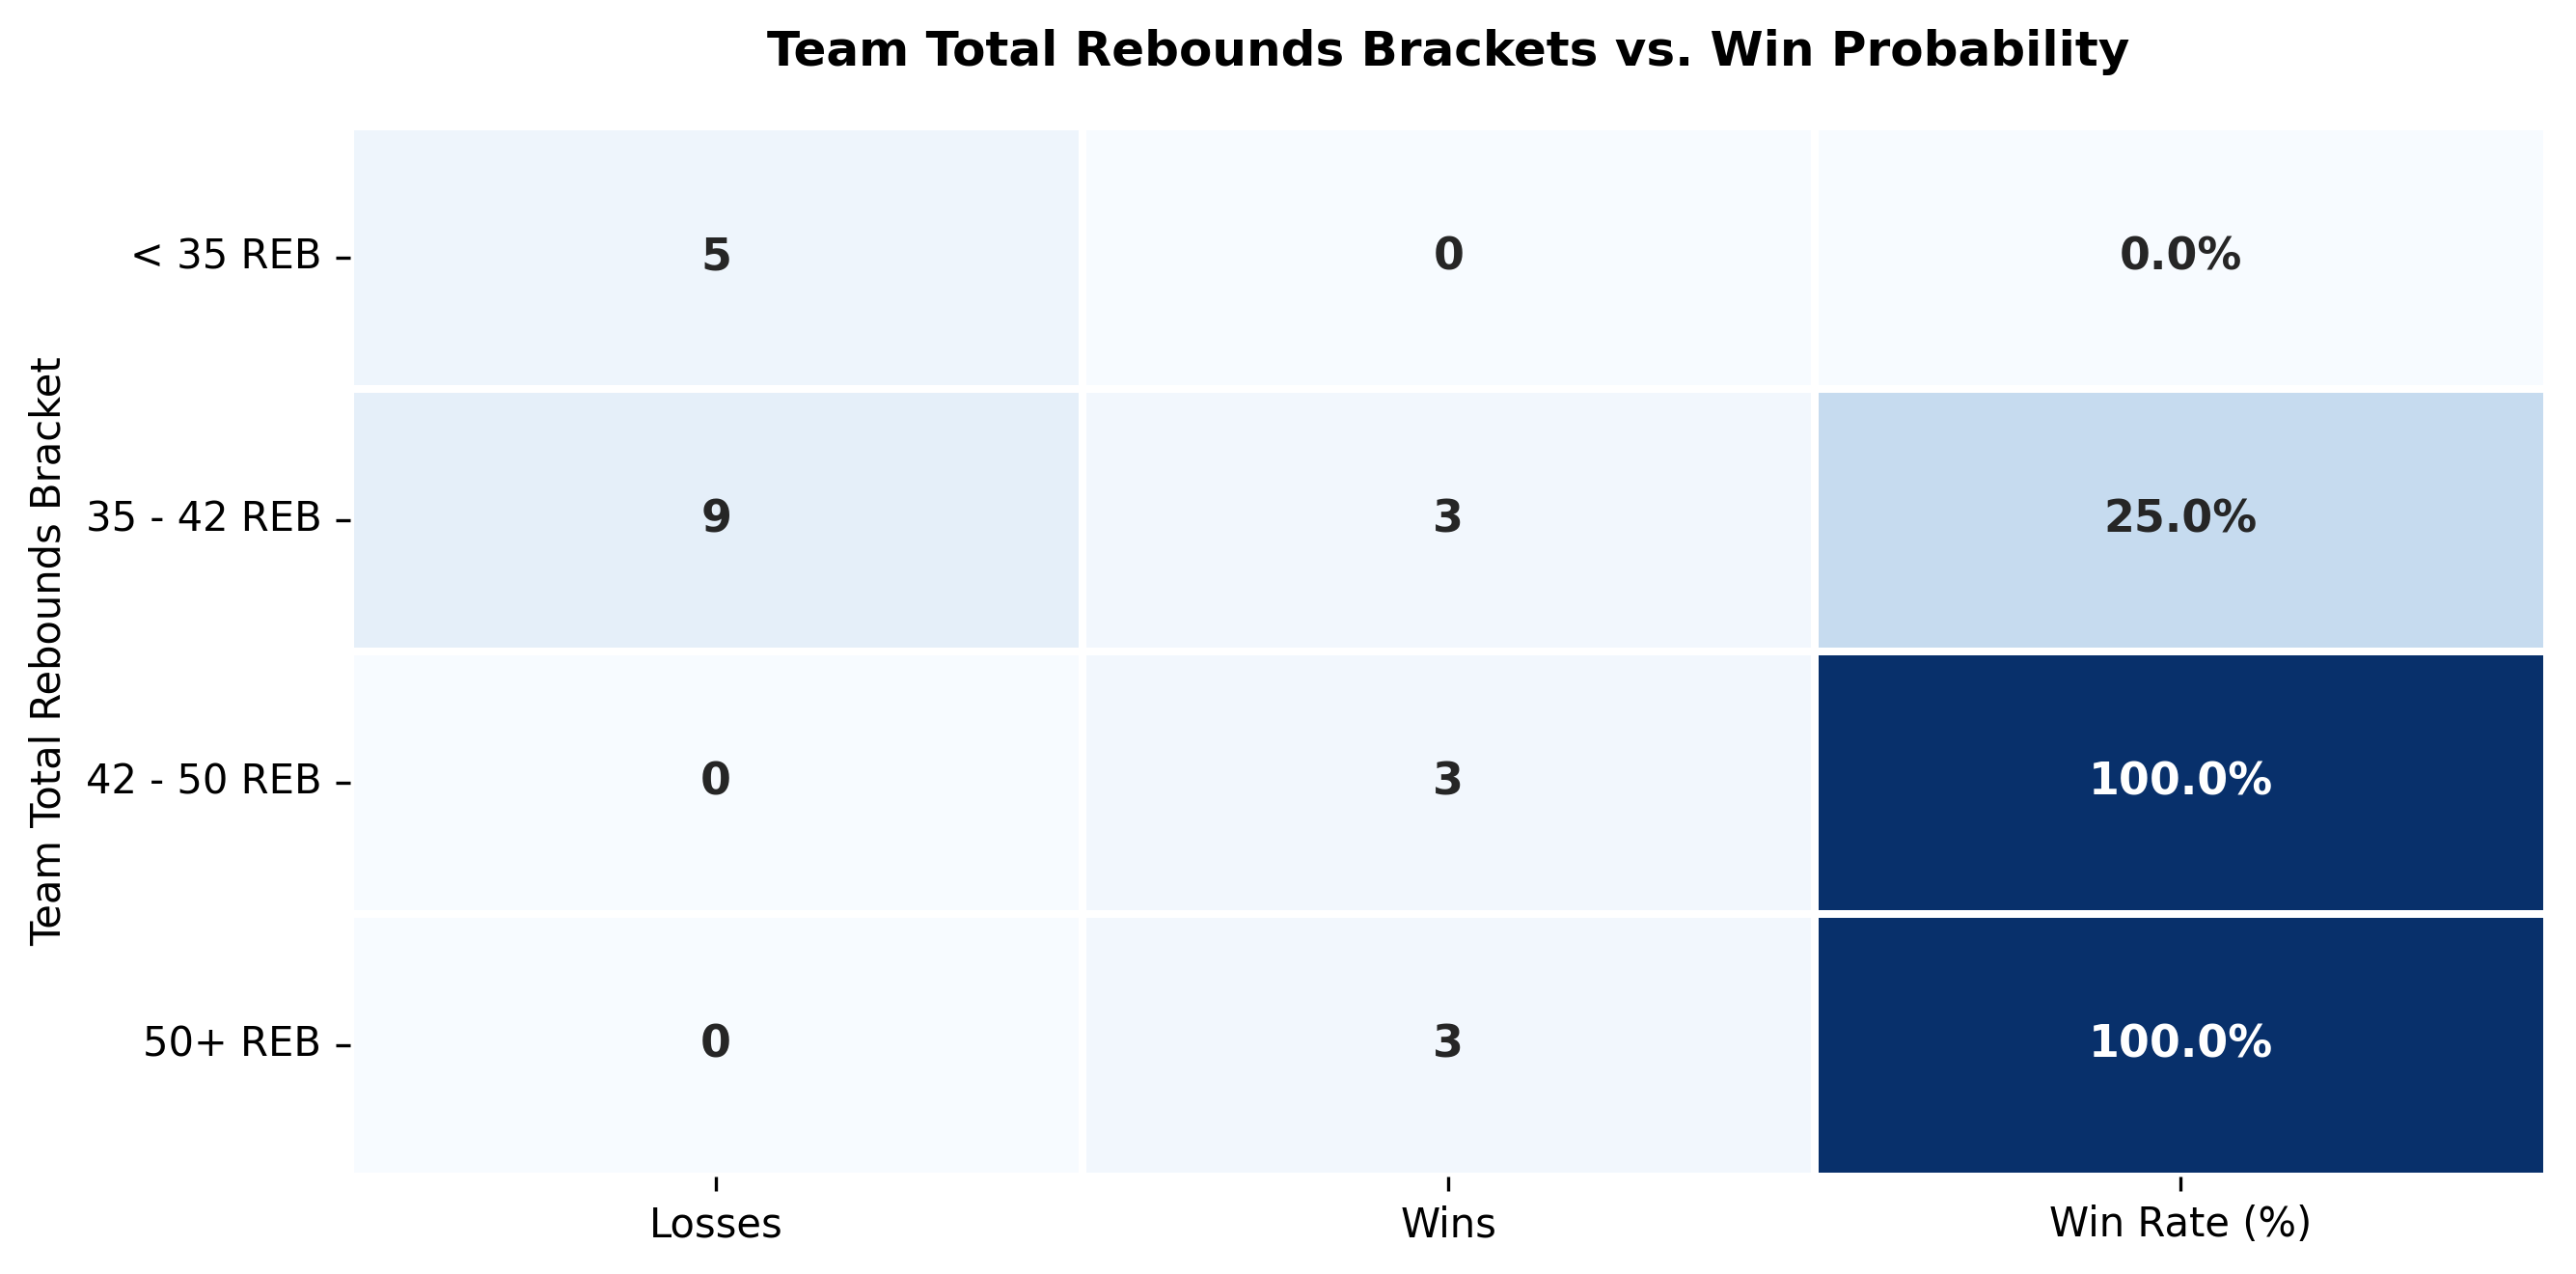

In [66]:
# Adjust bin edges (e.g., 35, 42, 50) to fit your team's rebounding averages
bin_edges = [0, 35, 42, 50, float('inf')]
bin_labels = ['< 35 REB', '35 - 42 REB', '42 - 50 REB', '50+ REB']

df_games['REB_Bin'] = pd.cut(
    df_games['Team_REB'],
    bins=bin_edges,
    labels=bin_labels,
    include_lowest=True,
)

ct = pd.crosstab(df_games['REB_Bin'], df_games['Win'])

for col in [0, 1]:
  if col not in ct.columns:
    ct[col] = 0

ct = ct.rename(columns={0: 'Losses', 1: 'Wins'})
ct = ct.reindex(bin_labels, fill_value=0)

ct['Total Games'] = ct['Losses'] + ct['Wins']
ct['Win Rate (%)'] = np.where(
    ct['Total Games'] > 0, (ct['Wins'] / ct['Total Games'] * 100), 0.0
).round(1)

ct_display = ct[['Losses', 'Wins', 'Win Rate (%)']]

annot_matrix = ct_display.copy().astype(object)
annot_matrix['Losses'] = ct_display['Losses'].astype(str)
annot_matrix['Wins'] = ct_display['Wins'].astype(str)
annot_matrix['Win Rate (%)'] = ct_display['Win Rate (%)'].apply(
    lambda x: f'{x:.1f}%'
)

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=300)

sns.heatmap(
    ct_display,
    annot=annot_matrix.values,
    fmt='',
    cmap='Blues',
    cbar=False,
    linewidths=1.5,
    linecolor='white',
    annot_kws={'size': 11, 'weight': 'bold'},
    ax=ax,
)

ax.set_title(
    'Team Total Rebounds Brackets vs. Win Probability',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
ax.set_ylabel('Team Total Rebounds Bracket')
ax.tick_params(axis='y', rotation=0)

ax.set_xlabel(
    ''
)

plt.tight_layout()
plt.show()

In [67]:
# Check total games and list unique opponents/dates
print(f"Total rows in df_games: {len(df_games)}")
print(df_games[['Game_ID', 'Win']].to_string())

Total rows in df_games: 23
       Game_ID  Win
0      Blaze A    0
1      Blaze H    0
2     Blaze2 A    0
3      Blues A    1
4      Blues H    1
5     Blues2 H    1
6       Fury A    0
7       Fury H    0
8      Fury2 A    0
9     Ignite A    1
10    Ignite H    1
11   Ignite2 H    1
12     Kings A    0
13     Kings H    1
14    Kings2 H    0
15   Paisley A    0
16   Paisley H    0
17  Paisley2 H    1
18  Paisley3 H    0
19     Rocks A    0
20     Rocks H    0
21    Rocks2 A    0
22    Wolves H    1


In [68]:
sheets_in_data = set(df_raw['Game_ID'].unique())
print("In data but not in game_results:", sheets_in_data - game_results.keys())
print("In game_results but not in data:", game_results.keys() - sheets_in_data)

In data but not in game_results: set()
In game_results but not in data: set()
